# Aula 20 — Codificação de Huffman

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

A RTU pode acumular um bloco de eventos para transmissão ou arquivamento, e o servidor SCADA precisa recuperá-los sem perdas. A aplicação desta aula comprime a coluna `tipo` do histórico: início de faixa, término, pausa, retorno, alerta e conclusão. Instantes, IDs e outras variáveis do processo não estão incluídos no tamanho medido.

O catálogo de seis tipos é compartilhado pelas duas pontas. A distribuição vem de um histórico sintético de 90 faixas, com alertas e pausas em intervalos definidos. O experimento serve à telemetria e ao historiador; o processamento imediato de alarmes não aguarda o fechamento desse bloco.

## 2. Modelo e fundamentação

Huffman combina os dois nós menos frequentes até formar uma árvore. Folhas representam símbolos; caminhos de 0 e 1 formam códigos livres de prefixos. Para frequências $f_i$ e comprimentos $\ell_i$, o payload tem $B_H=\sum_i f_i\ell_i$ bits. A árvore minimiza o comprimento médio entre códigos binários de prefixo para essas frequências. A construção com heap custa $O(m\log m)$ para $m$ símbolos; contar ocorrências custa $O(N)$.

O protocolo didático HF serializa: assinatura de 2 bytes, número de eventos de 4 bytes, número de símbolos de 1 byte e comprimento útil de 4 bytes. Cada entrada do dicionário contém ID (1 byte), comprimento (1 byte) e código preenchido até bytes inteiros. O payload também é preenchido e o quadro recebe CRC-32 (4 bytes). Assim:

$$S_H=11+\sum_i(2+\lceil\ell_i/8\rceil)+\lceil B_H/8\rceil+4.$$

A referência fixa FX usa assinatura, número de eventos, três bits por evento e o mesmo CRC: $S_F=6+\lceil3N/8\rceil+4$. Inteiros são big-endian. Um único símbolo recebe código `0`; uma mensagem vazia possui apenas cabeçalho e CRC.

## 3. Procedimento e demonstração

1. Mostrar frequências, fusões e códigos da árvore.
2. Serializar um pacote HF real em bytes, incluindo seu dicionário.
3. Decodificar somente a partir dos bytes, sem fornecer a árvore original ao receptor.
4. Comparar payload e pacote completo com a codificação fixa.
5. Repetir com mensagem curta, distribuição equilibrada e pacote corrompido.

Pergunta para a apresentação: por que um alerta raro pode ter código longo? Porque frequência não representa prioridade operacional.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [1]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [2]:
def huffman(simbolos):
    freq = Counter(simbolos); seq = count(); fila = []
    for s, f in sorted(freq.items()):
        heapq.heappush(fila, (f, next(seq), {'s': s, 'f': f}))
    fusoes = []
    while len(fila) > 1:
        a, _, esq = heapq.heappop(fila); b, _, dire = heapq.heappop(fila)
        fusoes.append((a, b, a+b))
        heapq.heappush(fila, (a+b, next(seq), {'f': a+b, 'esq': esq, 'dir': dire}))
    raiz = fila[0][2] if fila else None
    codigos = {}; pendentes = [(raiz, '')] if raiz else []
    while pendentes:
        no, bits = pendentes.pop()
        if 's' in no: codigos[no['s']] = bits or '0'
        else: pendentes.extend([(no['dir'], bits+'1'), (no['esq'], bits+'0')])
    return raiz, codigos, fusoes


In [3]:
def comprimir(simbolos):
    if any(type(s) is not int or s not in range(6) for s in simbolos):
        raise ValueError('Tipo de evento inválido')
    _, codigos, _ = huffman(simbolos)
    bits = ''.join(codigos[s] for s in simbolos)
    dicionario = b''.join(bytes([s, len(c)])+bits_bytes(c) for s, c in sorted(codigos.items()))
    data = struct.pack('>2sIBI', b'HF', len(simbolos), len(codigos), len(bits))
    return com_crc(data+dicionario+bits_bytes(bits))


def descomprimir(pacote):
    data = sem_crc(pacote)
    if len(data) < 11: raise ValueError('Cabeçalho incompleto')
    magic, n, m, nbits = struct.unpack('>2sIBI', data[:11])
    if magic != b'HF' or m > 6: raise ValueError('Cabeçalho inválido')
    pos = 11; codigos = {}; ids = set()
    for _ in range(m):
        if pos+2 > len(data): raise ValueError('Dicionário truncado')
        s, tamanho = data[pos:pos+2]; pos += 2
        if s >= 6 or s in ids or not 1 <= tamanho <= 5: raise ValueError('Código inválido')
        c = bytes_bits(data[pos:pos+(tamanho+7)//8], tamanho); pos += (tamanho+7)//8
        if any(c.startswith(outro) or outro.startswith(c) for outro in codigos):
            raise ValueError('Dicionário não prefixo')
        codigos[c] = s; ids.add(s)
    bits = bytes_bits(data[pos:], nbits); prefixo = ''; resultado = []
    for b in bits:
        prefixo += b
        if prefixo in codigos: resultado.append(codigos[prefixo]); prefixo = ''
        elif not any(c.startswith(prefixo) for c in codigos): raise ValueError('Prefixo inválido')
    if prefixo or len(resultado) != n or (n == 0) != (m == 0):
        raise ValueError('Mensagem incompleta')
    return resultado


### Frequências e códigos

In [4]:
seq=[e['tipo'] for e in gerar_eventos()]
root,cod,fusoes=huffman(seq)
for ident,f in sorted(Counter(seq).items()):print(ident,EVENTOS[ident],f,cod[ident])
print('Fusões:',fusoes)
assert descomprimir(comprimir(seq))==seq

0 INICIO_FAIXA 90 11
1 FIM_FAIXA 90 0
2 PAUSA 6 1011
3 RETORNO 1 10100
4 ALERTA 6 100
5 CONCLUSAO 1 10101
Fusões: [(1, 1, 2), (2, 6, 8), (6, 8, 14), (14, 90, 104), (90, 104, 194)]


### Pacotes completos e economia líquida

Histórico | fixo: 83 bytes | Huffman: 74 bytes | economia: 10.84 %
Curta | fixo: 12 bytes | Huffman: 28 bytes | economia: -133.33 %
Equilibrada | fixo: 33 bytes | Huffman: 53 bytes | economia: -60.61 %


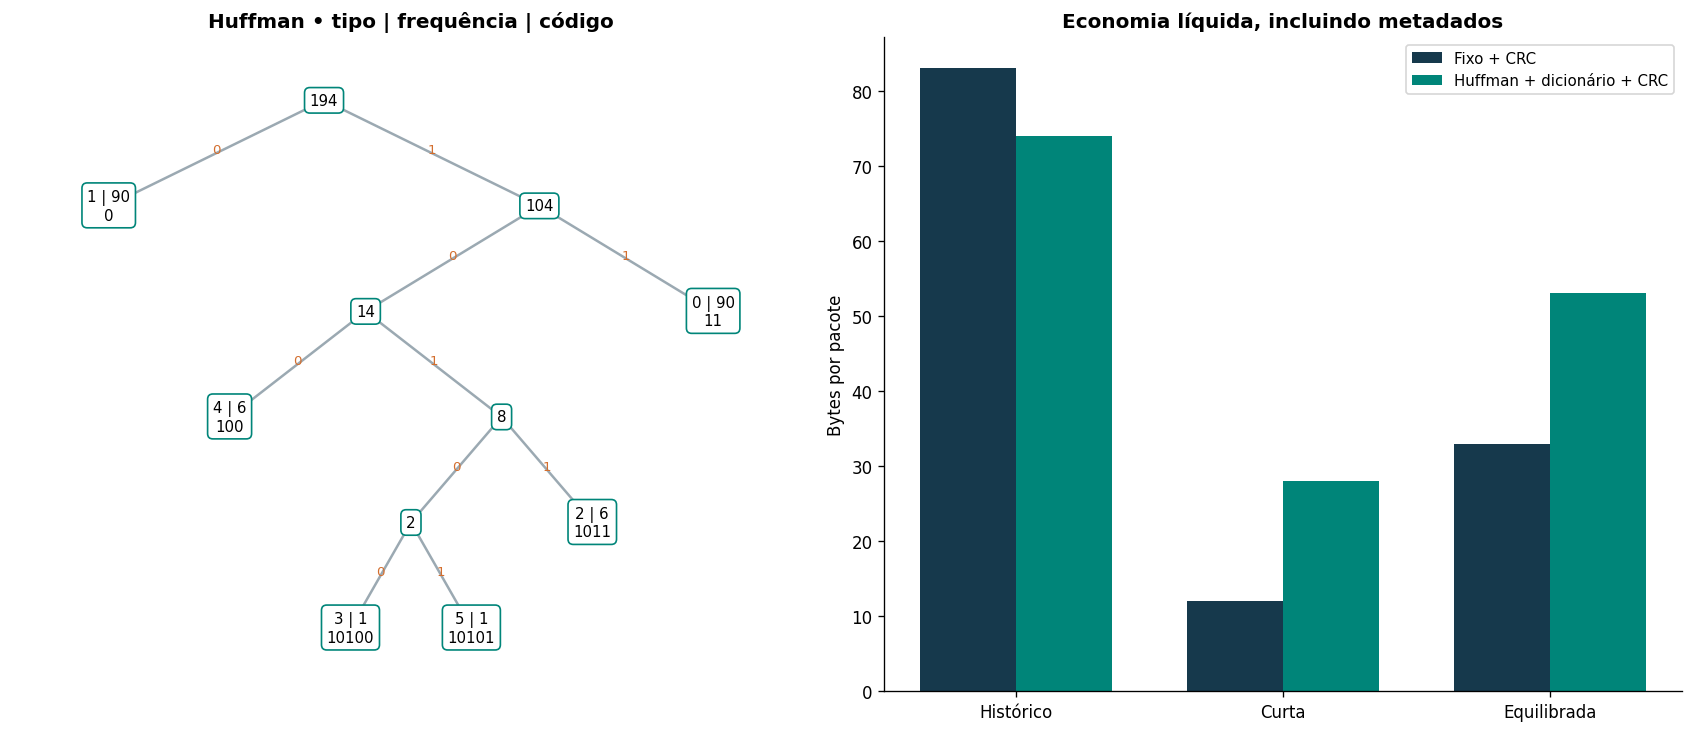

In [5]:
for nome,x in [('Histórico',seq),('Curta',[0,1,3,5]),('Equilibrada',list(range(6))*10)]:
    a,b=len(fixo(x)),len(comprimir(x))
    print(nome, '| fixo:',a,'bytes | Huffman:',b,'bytes | economia:',round(100*(1-b/a),2),'%')
vis.figura20();plt.show()

### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [6]:
RESUMO = TESTES[20]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 20: APROVADAS')

{
  "eventos": 194,
  "huffman_bytes": 74,
  "fixo_bytes": 83,
  "dicionario_bytes": 18
}
Verificações da aula 20: APROVADAS


## 5. Interpretação, limites e continuidade

O ganho depende do bloco e do formato transmitido. Não se usa o tamanho da string Python de zeros e uns como tamanho de comunicação. CRC detecta muitos erros acidentais, mas não é autenticação nem garantia absoluta de integridade. Não implementamos rádio, retransmissão ou protocolo industrial real.

A Aula 21 indexa os registros completos; Huffman preserva a sequência de tipos. Na Aula 28, a pequena sequência de eventos pode crescer após a compressão: o resultado negativo é mostrado, sem omitir o custo do dicionário.

## 6. Referências

- [Princeton — Data Compression](https://algs4.cs.princeton.edu/55compression/index.php).
- [Python — zlib e CRC-32](https://docs.python.org/3/library/zlib.html).
- [Referência curricular do professor](https://github.com/valerio-unifei/ECAA08-2026.2-Projeto/tree/main/etapa-03-arvores). Organização consultada em 16/11/2026; aplicações e figuras desta entrega são do drone.